In [1]:
NAMES = ['Angela DiAndreth', 'Sergey Dutt', 'Edward Lombo-Becerra']

In [2]:
import jax
import jax.numpy as jnp
import numpy as np
import scipy.signal as signal
import matplotlib.pyplot as plt

In [3]:
from fix_data import get_random_subset, load_and_center_data  

In [4]:
df = load_and_center_data('Pendulum.xlsx')
subset_df = get_random_subset(df, 10)

t_start_orig = subset_df['Time'].iloc[0]
t_end_orig = subset_df['Time'].iloc[-1]

print(f"Subset original time window: {t_start_orig:.1f} s to {t_end_orig:.1f} s")

subset_df['Time'] = subset_df['Time'] - subset_df['Time'].iloc[0]

t_data = np.array(subset_df['Time'].values)
theta_data = np.array(subset_df['Angle'].values)

Subset original time window: 452.6 s to 478.7 s


In [5]:
def fourier_series(t_data, theta_data, max_K=10, tol=1e-2):
    # find peaks in subset
    peaks, _ = signal.find_peaks(theta_data)

    # average period
    t_diff = t_data[peaks[-1]] - t_data[peaks[0]]
    T_avg = t_diff / (len(peaks) - 1)
    # angular frequency
    freq = 2 * np.pi / T_avg

    first_peak = theta_data[peaks[0]]
    last_peak = theta_data[peaks[-1]]

    # decay constant
    Lambda = np.log(first_peak / last_peak) / t_diff
    decay = jnp.exp(-Lambda * t_data)

    # initial conditions 
    prev_mse = float('inf')
    best_a = None
    best_K = 1

    for K in range(1, max_K + 1):
        cols = []
        for k in range(1, K + 1):
            cols.append(decay * jnp.cos(k * freq * t_data))
            cols.append(decay * jnp.sin(k * freq * t_data))

        X = jnp.column_stack(cols)
        Y = theta_data

        # solve for [A_1, B_1, ..., A_K, B_K]
        a = jnp.linalg.solve(X.T @ X, X.T @ Y)

        # model prediction at current K
        f_series = X @ a

        # calculate MSE and check stopping condition
        curr_mse = float(jnp.mean((theta_data - f_series) ** 2))

        if K > 1:
            rel_improvement = (prev_mse - curr_mse) / prev_mse
            if rel_improvement < tol:
                # at less than 1% improvement; stop and keep previous K fit
                break

        # save current best coefficients and update MSE
        best_a = a
        best_K = K
        prev_mse = curr_mse

    # convert optimal coefficients to a static JAX array
    best_a_jnp = jnp.array(best_a)

    # CONTINUOUS FUNCTION THAT JAX.GRAD USES 
    def theta_func(t):
        decay_t = jnp.exp(-Lambda * t)
        summation = 0.0
        idx = 0
        for k in range(1, best_K + 1):
            summation = (
                summation
                + best_a_jnp[idx] * jnp.cos(k * freq * t)
                + best_a_jnp[idx + 1] * jnp.sin(k * freq * t)
            )
            idx += 2
        return decay_t * summation

    return theta_func, best_K

In [6]:
# get the continuous differentiable function and total K's used 
theta_func, final_K = fourier_series(t_data, theta_data)

# first and second derivatives (as functions of t)    
theta_dot_func = jax.grad(theta_func)
theta_ddot_func = jax.grad(theta_dot_func)

# evaluate derivatives at all time points t_data using vmap
theta_dot = jax.vmap(theta_dot_func)(t_data)
theta_ddot = jax.vmap(theta_ddot_func)(t_data)

print(f"Final selected K: {final_K}")

Final selected K: 4


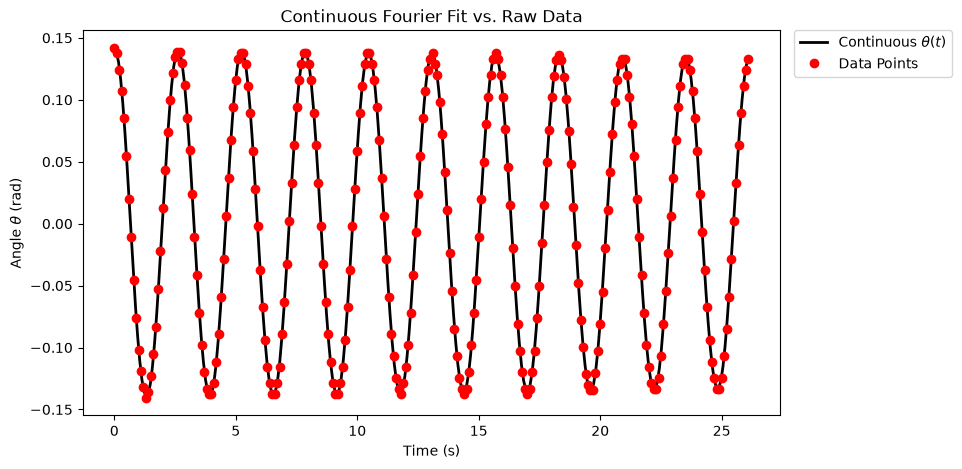

In [7]:
t_plot = jnp.linspace(t_data[0], t_data[-1], 300)
theta_plot = jax.vmap(theta_func)(t_plot)

# plot continuous f-series against discrete data points
plt.figure(figsize=(9, 5), dpi=100)
plt.plot(t_plot, theta_plot, label='Continuous $\\theta(t)$', color='black', linewidth=2)
plt.plot(t_data, theta_data, 'ro', label='Data Points')
plt.xlabel('Time (s)')
plt.ylabel('Angle $\\theta$ (rad)')
plt.title('Continuous Fourier Fit vs. Raw Data')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left', borderaxespad=0)
plt.show()

In [8]:
# linear regression for the differential equation                                                          
Y = theta_ddot
X = jnp.column_stack([-theta_dot, -jnp.sin(theta_data)])

a = jnp.linalg.solve(X.T @ X, X.T @ Y)
a1 = float(a[0])
a2 = float(a[1])

# model: theta'' + a1*theta' + a2*sin(theta) = 0                                     
# a1 = c / m*L^2, a2 = g/L, g = 9.81                                                 
g = 9.81 # m / s^2                                                                   
L_data = 1.615 # m                                                                   
m_data = 1 # kg                                                                      

L_model = g / a2
L_err = jnp.abs(L_model - L_data) * 100
C_model = a1 * m_data * (L_model**2)

print(f'L_model: {L_model:.3f} m')
print(f'L_model error: {float(L_err):.3f} cm')
print(f'Gamma: {a1:.3f}')
print(f'Air-Resistance Coef (C): {C_model:.3f}')

L_model: 1.692 m
L_model error: 7.705 cm
Gamma: 0.004
Air-Resistance Coef (C): 0.011


In [9]:
from scipy.integrate import solve_ivp
from scipy.optimize import curve_fit

In [10]:
def pendulum_model(t, y, gamma, L = 1.615, g = 9.81):
    """
    Parameters:
    t: current time point
    y: state vector [theta, omega]
    - theta is angular displacement
    - omega is angular velocity
    gamma: damping parameter
    L: length of the pendulum (1.615)
    g: acceleration due to gravity (9.81)
    """
    theta, omega = y
    dtheta_dt = omega
    domega_dt = -gamma * omega - (g / L) * np.sin(theta)

    return [dtheta_dt, domega_dt]

In [11]:
def solve_pendulum_ivp(t_eval, *params):
    theta_0 = subset_df['Angle'].iloc[0]
    omega_0 = 0 # no initial velocity
    y0 = [theta_0, omega_0]

    sol = solve_ivp(
        fun = pendulum_model,
        t_span = (t_eval[0], t_eval[-1]),
        y0 = y0,
        t_eval = t_eval,
        args = params, # args must be a tuple
        method = 'RK45',
    )

    return sol.y[0] # return theta values

In [12]:
# Plotting function for reusable plotting of data and model fit
def plot_model(time_data, angle_data, model_fun, fit_params, description = ''):
    """
    Generates plot of with model line and data points
    Works with 1 or multiple free parameters
    """
    plt.close('all') # close any open figures
    t_model = np.linspace(time_data.iloc[0], time_data.iloc[-1], 500)

    if isinstance(fit_params, (list, tuple, np.ndarray)):
        params = tuple(fit_params)
    else:
        params = (fit_params,)

    y_model = model_fun(t_model, *params)

    fig, ax = plt.subplots(figsize=(10, 6))
    ax.plot(
        time_data,
        angle_data,
        'ko',
        markersize = 3,
        label = 'Data',
    )

    # plot modeled trajectory
    ax.plot(t_model, y_model, color = 'crimson', linewidth = 2, label = 'Model')

    ax.set_xlabel('Time (s)')
    ax.set_ylabel('Angle (rad)')
    ax.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
    fig.suptitle(f'Pendulum Angle vs Time for {description}')
    plt.show()

Optimized Damping Coefficents -> gamma: 0.00500 ± 0.00016 s^-1
                              -> L:     1.69589 ± 0.0001 m


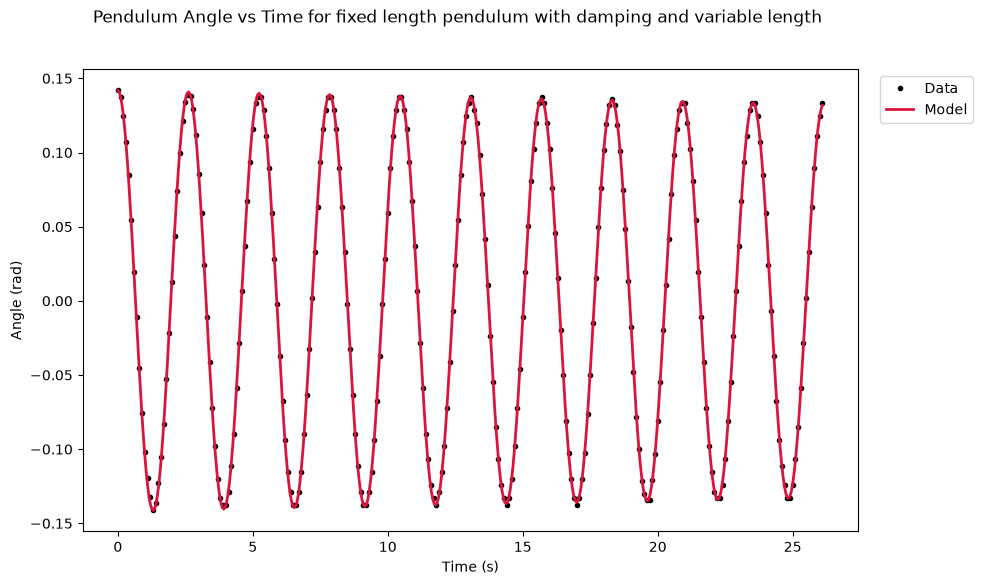

In [13]:
popt_2p, pcov_2p = curve_fit(
    solve_pendulum_ivp,
    subset_df['Time'].values,
    subset_df['Angle'].values,
    p0=[0.05, 1.615],  # initial guesses: gamma=0.05, L=1.615m
    bounds=([0.0, 1.0], [1.0, 2.0]),
)

gamma_fit, L_fit = popt_2p
gamma_err, L_err = np.sqrt(np.diag(pcov_2p))
print(f'Optimized Damping Coefficents -> gamma: {gamma_fit:.5f} ± {gamma_err:.5f} s^-1')
print(f'                              -> L:     {L_fit:.5f} ± {L_err:.4f} m')

plot_model(
    time_data = subset_df['Time'],
    angle_data = subset_df['Angle'],
    model_fun = solve_pendulum_ivp,
    fit_params = (gamma_fit, L_fit),
    description = 'fixed length pendulum with damping and variable length'
)